# Stage 1: Disease signature extraction

Turns a GEO2R full results table into the up/down gene lists that the repurposing stage (Person B) needs.
Used for heart failure (GSE57338) and, with the same settings, rheumatoid arthritis.

**Steps:** load table -> clean probes -> check the sign convention -> remove sex-linked genes -> pick up/down genes -> export.

## 1. Config
Change only this cell when switching disease.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path("..").resolve()

DISEASE = "hf"                      # "hf" or "ra"
INPUT_FILE = REPO / "data/raw/hf/GSE57338_top_table.tsv"
PADJ_CUTOFF = 0.05
N_PER_DIRECTION = 150               # genes kept on each side (LINCS-style signature)
FLIP_SIGN = False                   # set True if logFC > 0 means HIGHER IN CONTROL in your table

# Known biology used to verify the sign. Positive logFC should mean higher in disease.
MARKERS = {
    "hf": {"up": ["NPPA", "FRZB", "SMOC2", "COL1A1"], "down": ["MYH6"]},
    "ra": {"up": ["MMP1", "MMP3", "CXCL13"], "down": []},   # check these against RA literature
}

# Sex-linked genes: group imbalance in sex shows up as fake disease signal
SEX_GENES = {"EIF1AY", "USP9Y", "DDX3Y", "KDM5D", "UTY", "ZFY", "RPS4Y1", "RPS4Y2", "TXLNGY",
             "NLGN4Y", "TMSB4Y", "PRKY", "SRY", "TBL1Y", "PCDH11Y", "XIST", "TSIX", "KDM6A", "DDX3X"}

OUT_DIR = REPO / "signature/results" / DISEASE
FIG_DIR = REPO / "signature/figures"
OUT_DIR.mkdir(parents=True, exist_ok=True); FIG_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load the GEO2R table

In [2]:
df = pd.read_csv(INPUT_FILE, sep="\t")
df = df.rename(columns={"Gene symbol": "Gene.symbol", "Gene title": "Gene.title",
                        "log2(fold change)": "logFC"})
need = {"adj.P.Val", "logFC", "Gene.symbol"}
assert need <= set(df.columns), f"Missing columns: {need - set(df.columns)}"
print(df.shape)
df.head()

(33297, 8)


,ID,adj.P.Val,P.Value,t,B,logFC,Gene.symbol,Gene.title
0,7976496,3.780000e-70,1.140000e-74,-24.4,159.142735,-2.640,SERPINA3,serpin family A member 3
1,8045291,1.480000e-65,8.870000e-70,-23.1,148.021408,-0.995,TUBA3D///TUBA3E///TUBA3C,tubulin alpha 3d///tubulin alpha 3e///tubulin ...
2,7992987,9.560000e-65,8.610000e-69,-22.9,145.776792,-0.668,HMOX2,heme oxygenase 2
3,8160168,2.020000e-64,2.420000e-68,22.7,144.754763,1.050,FREM1,FRAS1 related extracellular matrix 1
4,7982204,1.660000e-62,2.500000e-66,22.2,140.174633,0.704,HMGN2,high mobility group nucleosomal binding domain 2


## 3. Clean probes
GEO2R reports probes, not genes. Drop probes with no gene symbol, drop multi-gene probes (`///`), then keep the most significant probe per gene.

In [3]:
n_probes = len(df)
df = df[df["Gene.symbol"].notna() & (df["Gene.symbol"].astype(str).str.strip() != "")]
n_annot = len(df)
df = df[~df["Gene.symbol"].str.contains("///")]
n_single = len(df)
df = df.sort_values("adj.P.Val").drop_duplicates("Gene.symbol", keep="first")
n_genes = len(df)

if FLIP_SIGN:
    df["logFC"] = -df["logFC"]

print(f"probes {n_probes} -> annotated {n_annot} -> single-gene {n_single} -> unique genes {n_genes}")
print(f"genes with adj.P.Val < {PADJ_CUTOFF}: {(df['adj.P.Val'] < PADJ_CUTOFF).sum()}")

probes 33297 -> annotated 22170 -> single-gene 19816 -> unique genes 18615
genes with adj.P.Val < 0.05: 9795


## 4. Sign check
Positive logFC must mean *higher in disease*. If the markers disagree, the contrast is probably reversed: set `FLIP_SIGN = True` and re-run.

In [4]:
m = MARKERS[DISEASE]
rows = []
for direction, genes in m.items():
    for g in genes:
        hit = df[df["Gene.symbol"] == g]
        if len(hit):
            lfc = float(hit["logFC"].iloc[0])
            ok = (lfc > 0) if direction == "up" else (lfc < 0)
            rows.append({"gene": g, "expected": direction, "logFC": lfc, "consistent": ok})
chk = pd.DataFrame(rows)
display(chk)
agree = chk["consistent"].mean() if len(chk) else np.nan
print(f"markers consistent with 'positive = higher in disease': {agree:.0%}")
if agree < 0.5:
    print("WARNING: sign looks reversed. Set FLIP_SIGN = True and re-run.")

,gene,expected,logFC,consistent
0,NPPA,up,1.730,True
1,FRZB,up,1.360,True
2,SMOC2,up,1.190,True
3,COL1A1,up,0.382,True
4,MYH6,down,-1.580,True


markers consistent with 'positive = higher in disease': 100%


## 5. Remove sex-linked genes

In [5]:
found = sorted(set(df["Gene.symbol"]) & SEX_GENES)
print("removing:", found)
df = df[~df["Gene.symbol"].isin(SEX_GENES)]

removing: ['DDX3X', 'DDX3Y', 'EIF1AY', 'KDM5D', 'KDM6A', 'NLGN4Y', 'PRKY', 'RPS4Y1', 'RPS4Y2', 'SRY', 'TBL1Y', 'TMSB4Y', 'TXLNGY', 'USP9Y', 'UTY', 'ZFY']


## 6. Threshold sensitivity
How many genes survive different fold-change cutoffs (for the methods section).

In [6]:
sig = df[df["adj.P.Val"] < PADJ_CUTOFF]
rows = []
for c in [0.2, 0.3, 0.4, 0.5, 1.0]:
    s = sig[sig["logFC"].abs() > c]
    rows.append({"|logFC| >": c, "genes": len(s), "up": int((s.logFC > 0).sum()), "down": int((s.logFC < 0).sum())})
pd.DataFrame(rows)

,|logFC| >,genes,up,down
0,0.2,3088,1543,1545
1,0.3,1481,778,703
2,0.4,755,403,352
3,0.5,421,224,197
4,1.0,45,22,23


## 7. Pick the signature
Top genes by fold change in each direction, among genes passing the adjusted p-value cutoff.

In [7]:
up = sig.sort_values("logFC", ascending=False).head(N_PER_DIRECTION)
down = sig.sort_values("logFC").head(N_PER_DIRECTION)
print(f"up: {len(up)} genes, logFC >= {up.logFC.min():.2f}")
print(f"down: {len(down)} genes, logFC <= {down.logFC.max():.2f}")
print("top up:  ", up["Gene.symbol"].head(10).tolist())
print("top down:", down["Gene.symbol"].head(10).tolist())

up: 150 genes, logFC >= 0.57
down: 150 genes, logFC <= -0.56
top up:   ['ASPN', 'SFRP4', 'NPPA', 'HBB', 'FRZB', 'OGN', 'COL14A1', 'LUM', 'MXRA5', 'SMOC2']
top down: ['SERPINA3', 'PLA2G2A', 'FCN3', 'IL1RL1', 'MYH6', 'CD163', 'SERPINE1', 'LYVE1', 'SLCO4A1', 'VSIG4']


## 8. Volcano plot

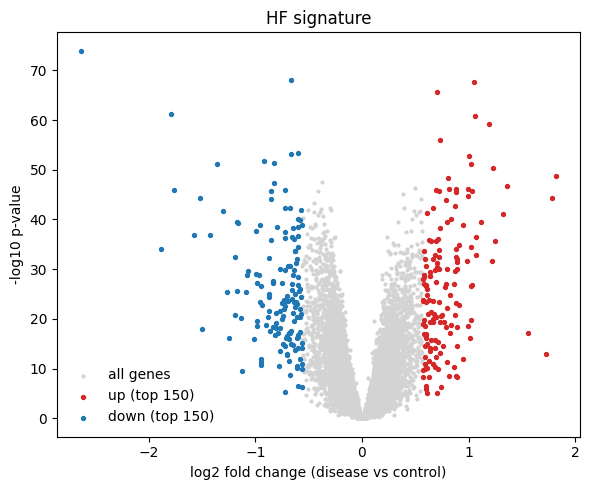

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
x, y = df["logFC"], -np.log10(df["P.Value"]) if "P.Value" in df else -np.log10(df["adj.P.Val"])
ax.scatter(x, y, s=4, c="lightgrey", label="all genes")
ax.scatter(up["logFC"], -np.log10(up["P.Value"]) if "P.Value" in up else -np.log10(up["adj.P.Val"]),
           s=8, c="#d62728", label=f"up (top {N_PER_DIRECTION})")
ax.scatter(down["logFC"], -np.log10(down["P.Value"]) if "P.Value" in down else -np.log10(down["adj.P.Val"]),
           s=8, c="#1f77b4", label=f"down (top {N_PER_DIRECTION})")
ax.set_xlabel("log2 fold change (disease vs control)"); ax.set_ylabel("-log10 p-value")
ax.set_title(f"{DISEASE.upper()} signature"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / f"{DISEASE}_volcano.png", dpi=200); plt.show()

## 9. Export (see docs/data-contract.md)

In [9]:
up["Gene.symbol"].to_csv(OUT_DIR / f"{DISEASE}_signature_up.txt", index=False, header=False)
down["Gene.symbol"].to_csv(OUT_DIR / f"{DISEASE}_signature_down.txt", index=False, header=False)
df.to_csv(OUT_DIR / f"{DISEASE}_full_results.csv", index=False)
print("saved to", OUT_DIR)

saved to /home/claude/capstone-repurposing/signature/results/hf


## Notes
- Not done yet: adjustment for etiology (DCM vs ICM) in HF, and replication on a second cohort (e.g. GSE141910 for HF, GSE55235 for RA).
- HBB (hemoglobin) can appear in the up list from blood in the tissue. Drop it if you want a cleaner signature.